# Actor with concurrency groups

The builder writes an actor class whose methods run in separate concurrency groups: up to four I/O calls at once, compute calls one at a time.

**When to use it.** One actor that serves both slow I/O calls and CPU-bound calls, where the slow calls must not block the others.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

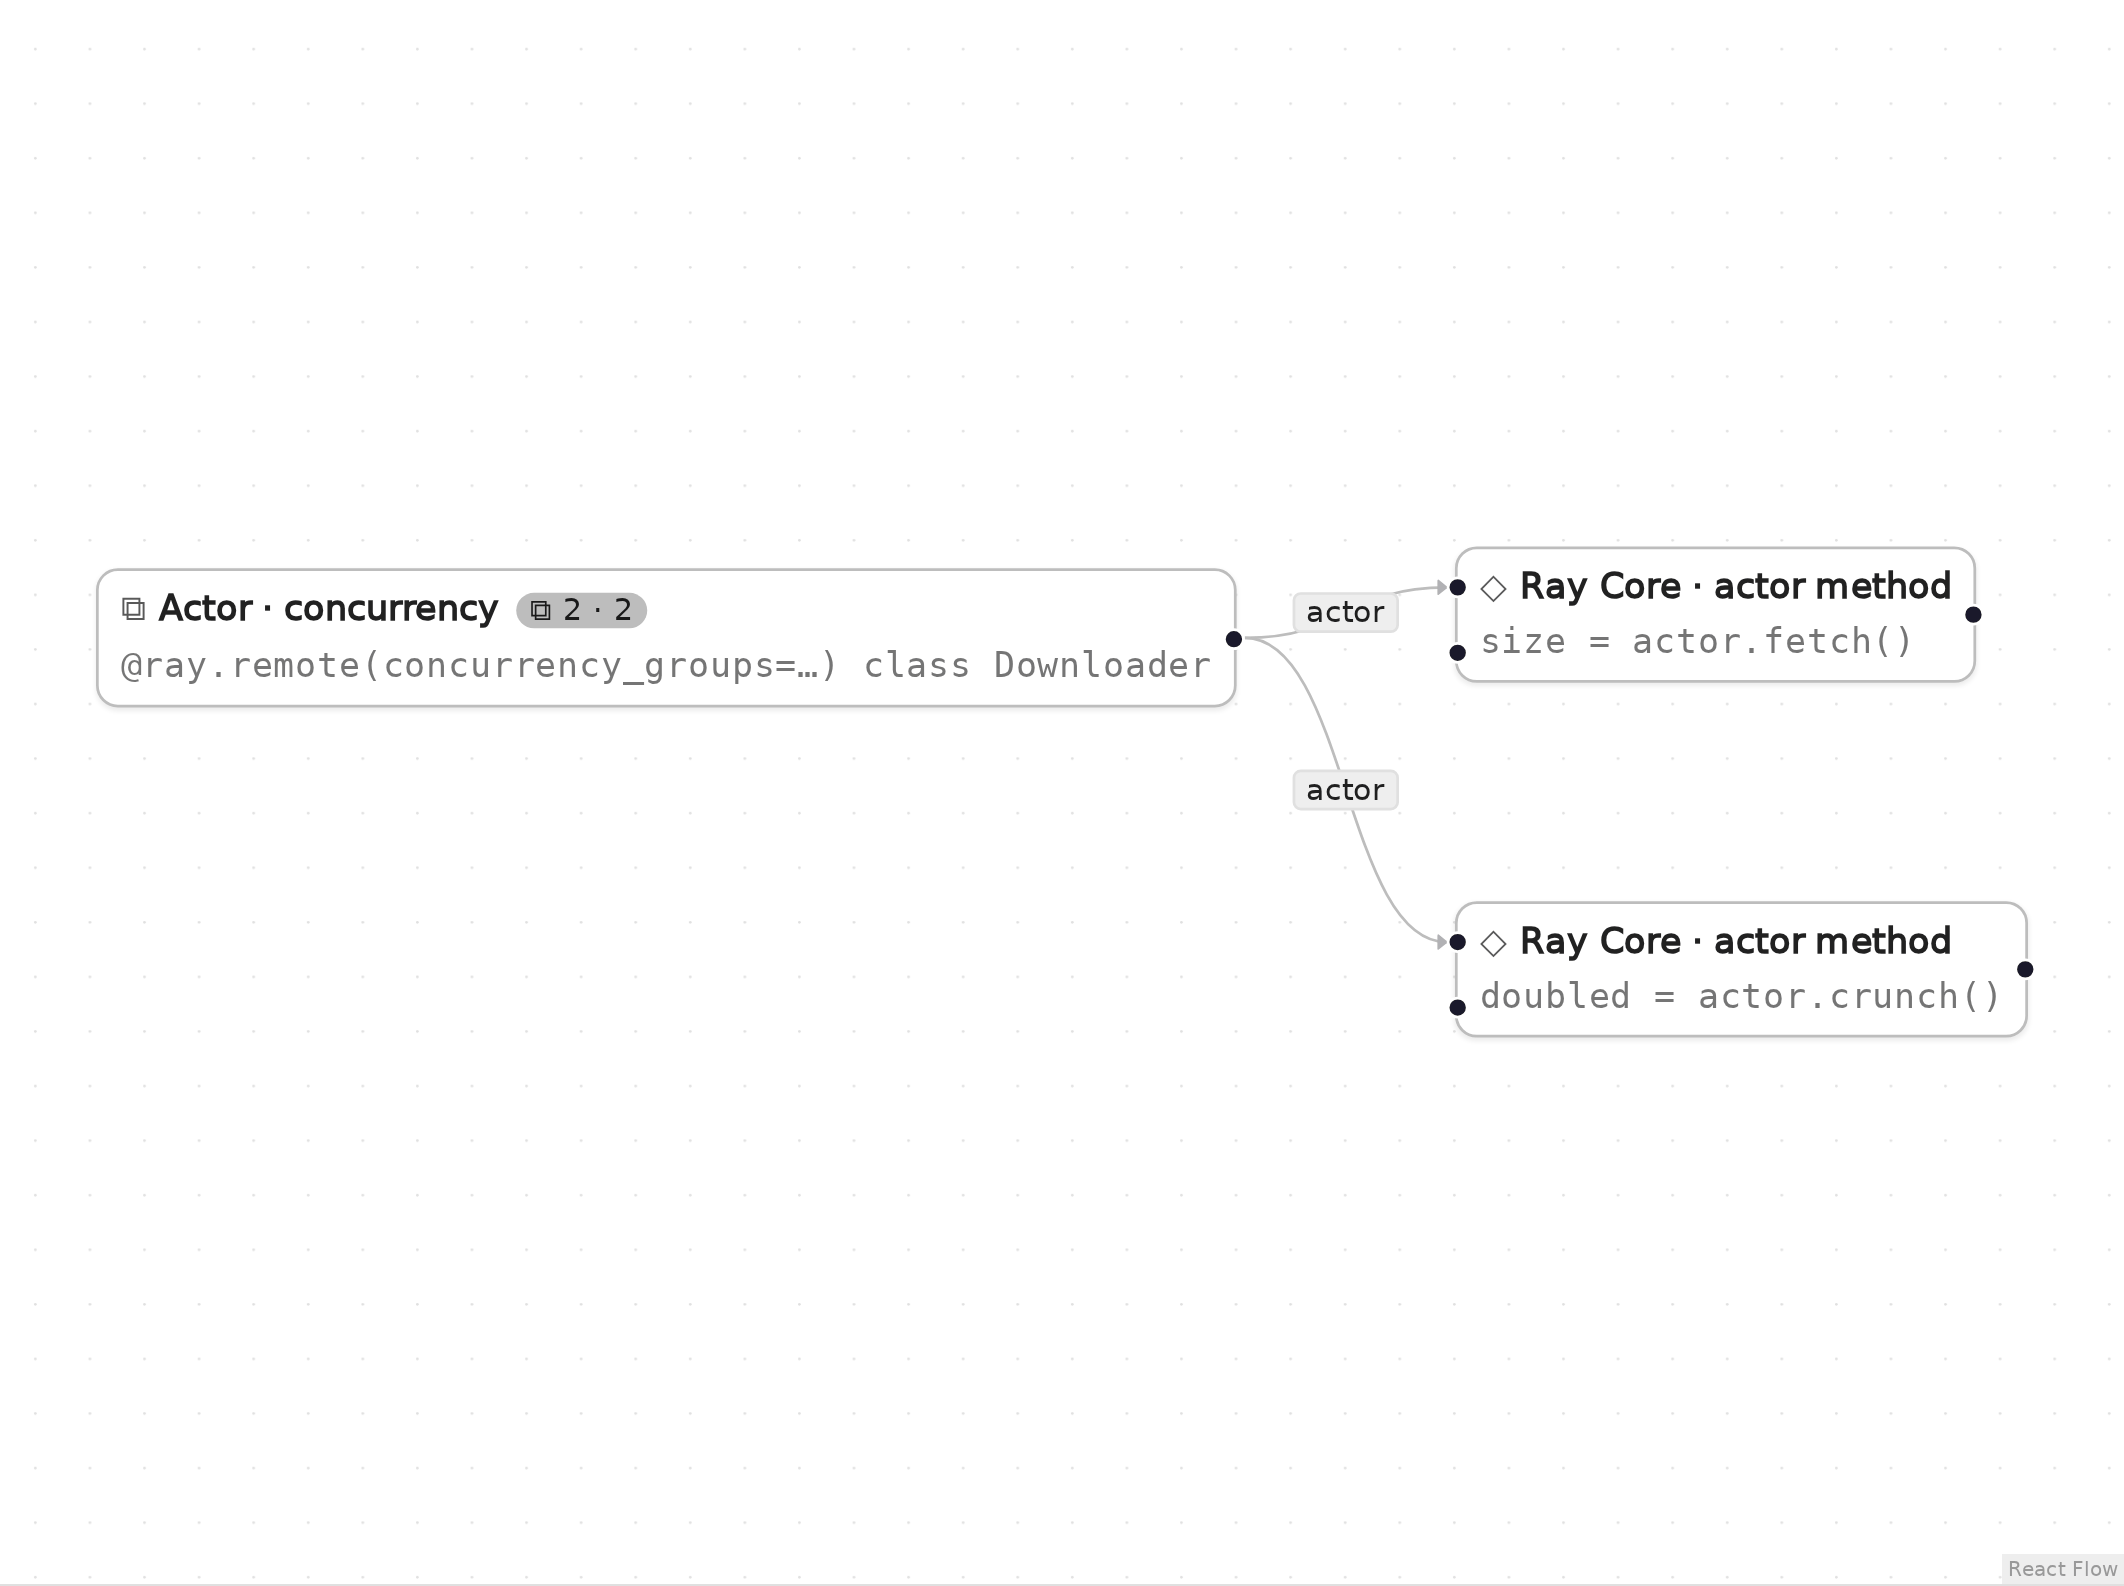

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
# The actor class itself is written by the builder from the node's settings.
# Its method bodies use the time module, so import it here.
import time

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

@ray.remote(concurrency_groups={"io": 4, "compute": 1})
class Downloader:
    @ray.method(concurrency_group="io")
    def fetch(self, url):
        time.sleep(0.1)
        return len(url)

    @ray.method(concurrency_group="compute")
    def crunch(self, x):
        return x * 2

dl = Downloader.remote()
_m1 = dl.fetch.remote("https://example.com")
size = ray.get(_m1)
_m2 = dl.crunch.remote(21)
doubled = ray.get(_m2)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert size == len("https://example.com"), size
assert doubled == 42, doubled
print("size =", size, "doubled =", doubled)

size = 19 doubled = 42


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Actor (concurrency)** (node `a1`, lines 8–13, 15–17 and 19)

```python
@ray.remote(concurrency_groups={"io": 4, "compute": 1})
class Downloader:
    @ray.method(concurrency_group="io")
    def fetch(self, url):
        time.sleep(0.1)
        return len(url)
...
    @ray.method(concurrency_group="compute")
    def crunch(self, x):
        return x * 2
...
dl = Downloader.remote()
```

concurrency_groups on @ray.remote declares two thread pools; @ray.method(concurrency_group=...) assigns each method to one. The builder writes the class from the node settings.

**Actor method** (node `m1`, lines 20–21)

```python
_m1 = dl.fetch.remote("https://example.com")
size = ray.get(_m1)
```

fetch runs in the io group, so up to four calls can overlap.

**Actor method** (node `m2`, lines 22–23)

```python
_m2 = dl.crunch.remote(21)
doubled = ray.get(_m2)
```

crunch runs in the compute group, one call at a time, unaffected by slow fetches.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()